# Module 16 — Neural Networks from Scratch

This notebook builds a multi-layer perceptron in NumPy, piece by piece: a hidden layer that solves XOR,
an activation gallery with derivatives, the batch-first forward pass, the softmax cross-entropy loss and
its gradient, `Dense`/`ReLU`/`MLP` classes with a gradient-checked backward pass, SGD and Adam, a complete
training loop that reaches about 97 percent test accuracy on the `load_digits` images in a couple of
seconds, and then the experiments behind the design rules: initialisation scale, vanishing gradients,
residual connections, batch normalisation, dropout and convolution-as-a-matrix.

Read the [concept guide](README.md) first, or keep it open alongside: the section numbers below match
its numbered concepts. **Conventions:** data matrices are `(n_samples, n_features)`, a layer computes
`X @ W + b` with `W` of shape `(n_in, n_out)`, and `G` always denotes the gradient of the loss with
respect to the quantity a layer produced.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. From linear models to networks: XOR

A single affine unit $\hat y = \sigma(x^\top w + b)$ draws one straight line. XOR — true for $(0,1)$ and $(1,0)$,
false for $(0,0)$ and $(1,1)$ — cannot be separated by any line (add the two positive-point inequalities
and the two negative-point inequalities and you get a contradiction). Let us watch logistic regression
fail, then add a hidden layer of two units and watch it succeed.

$$
f(x) = \tanh(x W_1 + b_1)\, W_2 + b_2, \qquad W_1 \in \mathbb{R}^{2 \times h},\ W_2 \in \mathbb{R}^{h \times 1}.
$$

logistic regression: loss 0.6931 (ln 2 = 0.6931), accuracy 0.50, w = [0. 0.], b = 0.000
2-4-1 network:      loss 0.0009, accuracy 1.00, predictions [0.0004 0.9988 0.9993 0.0013]
parameters: 2*4 + 4 + 4*1 + 1 = 17


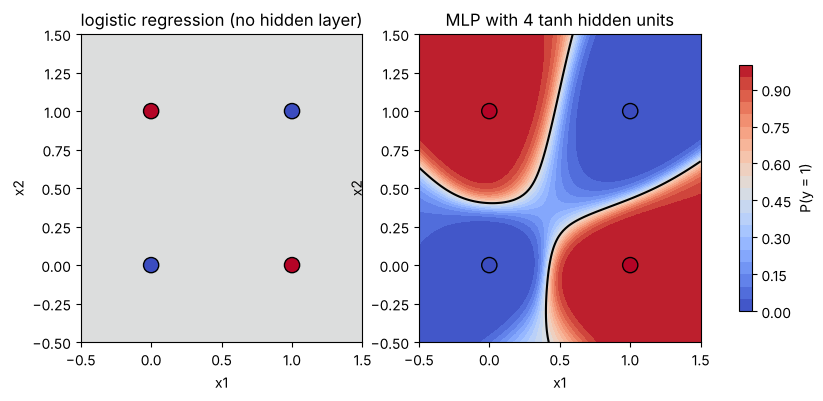

In [2]:
X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = np.array([0., 1., 1., 0.])
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))
bce = lambda p, y: -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# (a) logistic regression = zero hidden layers
w, b = np.zeros(2), 0.0
for step in range(2000):
    p = sigmoid(X_xor @ w + b)
    g = (p - y_xor) / 4                       # dL/dz for BCE, averaged over the 4 points
    w -= 0.5 * X_xor.T @ g; b -= 0.5 * g.sum()
print(f"logistic regression: loss {bce(p, y_xor):.4f} (ln 2 = {np.log(2):.4f}), accuracy {np.mean((p > 0.5) == (y_xor == 1)):.2f}, w = {w}, b = {b:.3f}")

# (b) one hidden layer with h tanh units, trained by the backward pass we derive in Section 5
h = 4
W1 = rng.normal(0, 1 / np.sqrt(2), (2, h)); b1 = np.zeros(h)
W2 = rng.normal(0, 1 / np.sqrt(h), (h, 1)); b2 = np.zeros(1)
for step in range(3000):
    Z1 = X_xor @ W1 + b1; A1 = np.tanh(Z1)
    z2 = (A1 @ W2 + b2)[:, 0]; p = sigmoid(z2)
    G2 = ((p - y_xor) / 4)[:, None]           # (4, 1)
    dW2 = A1.T @ G2; db2 = G2.sum(0)
    G1 = (G2 @ W2.T) * (1 - A1 ** 2)          # back through W2, then through tanh
    dW1 = X_xor.T @ G1; db1 = G1.sum(0)
    W1 -= 0.5 * dW1; b1 -= 0.5 * db1; W2 -= 0.5 * dW2; b2 -= 0.5 * db2
print(f"2-{h}-1 network:      loss {bce(p, y_xor):.4f}, accuracy {np.mean((p > 0.5) == (y_xor == 1)):.2f}, predictions {p}")
n_params = 2 * h + h + h * 1 + 1
print(f"parameters: 2*{h} + {h} + {h}*1 + 1 = {n_params}")

gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 120), np.linspace(-0.5, 1.5, 120))
grid = np.c_[gx.ravel(), gy.ravel()]
p_lin = sigmoid(grid @ w + b).reshape(gx.shape)
p_net = sigmoid((np.tanh(grid @ W1 + b1) @ W2 + b2)[:, 0]).reshape(gx.shape)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, P, title in zip(axes, [p_lin, p_net], ["logistic regression (no hidden layer)", f"MLP with {h} tanh hidden units"]):
    cs = ax.contourf(gx, gy, P, levels=20, cmap="coolwarm", vmin=0, vmax=1)
    ax.contour(gx, gy, P, levels=[0.5], colors="k")
    ax.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=120, edgecolor="k", vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
fig.colorbar(cs, ax=axes, label="P(y = 1)", shrink=0.8)
plt.show()

Logistic regression ends at the uninformed loss $\ln 2 = 0.693$ with its weights at zero — the best a
line can do is predict 0.5 everywhere. The hidden layer bends the decision surface into a band around
the diagonal and reaches 100 percent with a dozen parameters. Every hidden unit is itself a line in
input space; the output layer combines *which side of which lines* a point lies on. That is the entire
idea of a neural network; the rest of this notebook is about doing it with matrices, fast and stably.

**Try it yourself:** set `h = 2` (the minimum) and re-run a few times with different seeds — it works for
some initialisations and gets stuck for others. Then try `h = 16`: does more width make the optimisation
easier or harder?

## 2. Activation functions and their derivatives

Without a nonlinearity, $L$ affine layers compose to one affine map: $(XW_1 + b_1)W_2 + b_2 = X(W_1W_2) + (b_1W_2 + b_2)$.
The activation is what makes depth count — and its *derivative* is what decides how much gradient
survives each layer on the way back. Let us plot the standard choices with their derivatives, and check
each derivative formula against central differences.

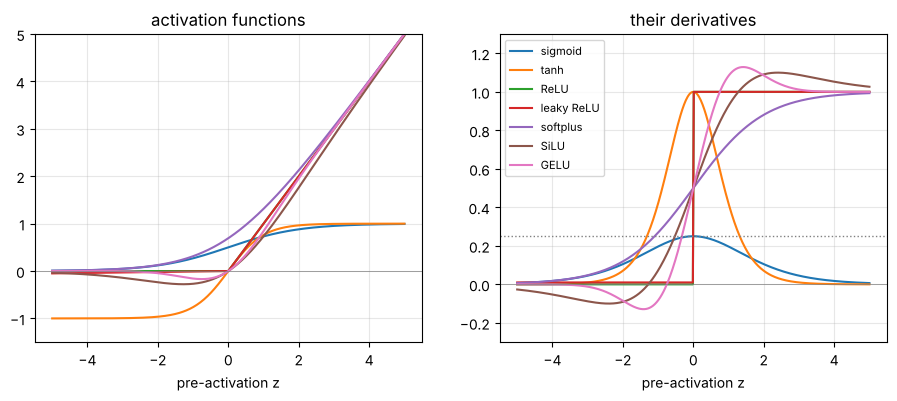

activation       f(2)    f'(2)   max |analytic - central difference| over z in [-2.   0.3  2. ]
sigmoid        0.8808   0.1050   2.2e-11
tanh           0.9640   0.0707   3.3e-11
ReLU           2.0000   1.0000   2.9e-11
leaky ReLU     2.0000   1.0000   2.9e-11
softplus       2.1269   0.8808   3.8e-11
SiLU           1.7616   1.0908   2.9e-11
GELU           1.9545   1.0852   9.9e-11


In [3]:
Phi = lambda z: 0.5 * (1 + erf(z / np.sqrt(2)))        # standard normal CDF
phi = lambda z: np.exp(-0.5 * z ** 2) / np.sqrt(2 * np.pi)

ACTS = {   # name: (function, analytic derivative)
    "sigmoid":    (sigmoid,                            lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh":       (np.tanh,                            lambda z: 1 - np.tanh(z) ** 2),
    "ReLU":       (lambda z: np.maximum(z, 0),         lambda z: (np.asarray(z) > 0).astype(float)),
    "leaky ReLU": (lambda z: np.where(z > 0, z, 0.01 * z), lambda z: np.where(z > 0, 1.0, 0.01)),
    "softplus":   (lambda z: np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0), sigmoid),
    "SiLU":       (lambda z: z * sigmoid(z),           lambda z: sigmoid(z) * (1 + z * (1 - sigmoid(z)))),
    "GELU":       (lambda z: z * Phi(z),               lambda z: Phi(z) + z * phi(z)),
}
z = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (f, df) in ACTS.items():
    axes[0].plot(z, f(z), label=name); axes[1].plot(z, df(z), label=name)
axes[0].set_title("activation functions"); axes[1].set_title("their derivatives")
for ax in axes:
    ax.set_xlabel("pre-activation z"); ax.axhline(0, color="gray", lw=0.5); ax.grid(alpha=0.3)
axes[0].set_ylim(-1.5, 5); axes[1].set_ylim(-0.3, 1.3); axes[1].axhline(0.25, color="gray", ls=":", lw=1); axes[1].legend(fontsize=8)
plt.show()

zs = np.array([-2.0, 0.3, 2.0]); hh = 1e-6
hdr_d = "f'(2)"
print(f"{'activation':12s} {'f(2)':>8s} {hdr_d:>8s}   max |analytic - central difference| over z in {zs}")
for name, (f, df) in ACTS.items():
    num = (f(zs + hh) - f(zs - hh)) / (2 * hh)
    print(f"{name:12s} {f(2.0):8.4f} {df(2.0):8.4f}   {np.max(np.abs(df(zs) - num)):.1e}")

Read the derivative panel: the sigmoid's slope never exceeds $1/4$ (dotted line) and is $0.105$ at $z = 2$;
tanh's is $0.071$ there. ReLU, SiLU and GELU pass the gradient essentially undiminished for positive
inputs — which is why they replaced sigmoids in deep networks (Section 7 measures the consequence). The
finite-difference column confirms every formula to $10^{-9}$ or better; keep this habit for every
derivative you ever write down.

## 3. The forward pass with matrices

Stack $n$ examples as the rows of $X \in \mathbb{R}^{n \times d}$. A layer is then one matrix product plus a broadcast bias,

$$
Z_1 = X W_1 + \mathbf{1} b_1^\top \in \mathbb{R}^{n \times h}, \qquad A_1 = \phi(Z_1), \qquad Z_2 = A_1 W_2 + \mathbf{1} b_2^\top \in \mathbb{R}^{n \times k},
$$

with the shape rule $(n \times n_{\text{in}})(n_{\text{in}} \times n_{\text{out}}) = (n \times n_{\text{out}})$. Here is the concept
guide's worked example — two examples, three features, two hidden ReLU units, one output — with every
intermediate printed. Keep these numbers: Section 5 runs the backward pass on them.

In [4]:
X = np.array([[1., 2., 0.], [0., 1., -1.]])
W1 = np.array([[0.5, -1.], [1., 0.5], [0., 2.]]); b1 = np.array([0.1, 0.2])
W2 = np.array([[1.], [-1.]]);                    b2 = np.array([0.5])
relu = lambda z: np.maximum(z, 0.0)

XW1 = X @ W1
Z1 = XW1 + b1               # broadcasting adds b1 to every row
A1 = relu(Z1)
Z2 = A1 @ W2 + b2
for name, arr in [("X", X), ("W1", W1), ("X @ W1", XW1), ("Z1 = X @ W1 + b1", Z1), ("A1 = relu(Z1)", A1), ("Z2 = A1 @ W2 + b2", Z2)]:
    print(f"{name:20s} shape {str(arr.shape):8s}\n{arr}\n")
n = X.shape[0]
flops = 2 * n * W1.shape[0] * W1.shape[1] + 2 * n * W2.shape[0] * W2.shape[1]
print(f"FLOPs for the two products: 2*{n}*3*2 + 2*{n}*2*1 = {flops}")
print(f"parameters: {W1.size + b1.size + W2.size + b2.size};  rule of thumb forward FLOPs = 2 * weights * batch = {2 * (W1.size + W2.size) * n}")

X                    shape (2, 3)  
[[ 1.  2.  0.]
 [ 0.  1. -1.]]

W1                   shape (3, 2)  
[[ 0.5 -1. ]
 [ 1.   0.5]
 [ 0.   2. ]]

X @ W1               shape (2, 2)  
[[ 2.5  0. ]
 [ 1.  -1.5]]

Z1 = X @ W1 + b1     shape (2, 2)  
[[ 2.6  0.2]
 [ 1.1 -1.3]]

A1 = relu(Z1)        shape (2, 2)  
[[2.6 0.2]
 [1.1 0. ]]

Z2 = A1 @ W2 + b2    shape (2, 1)  
[[2.9]
 [1.6]]

FLOPs for the two products: 2*2*3*2 + 2*2*2*1 = 32
parameters: 11;  rule of thumb forward FLOPs = 2 * weights * batch = 32


Notice the bias: `b1` has shape `(2,)` and is added to a `(2, 2)` matrix — NumPy copies it to every
row, which is exactly $\mathbf{1} b_1^\top$. The second example's second hidden unit is switched off
($Z_1 = -1.3 < 0$); remember that zero when we come to the gradients. The forward cost is about
$2 \times (\text{weights}) \times (\text{batch})$ FLOPs, and a training step about three times that.

## 4. Loss functions: softmax cross-entropy and its gradient

For $k$ classes the logits $Z \in \mathbb{R}^{n \times k}$ become probabilities row-wise with the softmax, and the loss is the
mean negative log-probability of the true class:

$$
P_{ij} = \frac{e^{Z_{ij}}}{\sum_c e^{Z_{ic}}}, \qquad \mathcal{L} = -\frac{1}{n}\sum_i \ln P_{i, y_i}, \qquad \frac{\partial \mathcal{L}}{\partial Z} = \frac{P - Y}{n}.
$$

Two implementation points. **Stability:** subtract the row maximum before exponentiating (log-sum-exp), so no
`exp` overflows and no `log(0)` is taken; compute $\ln P$ directly and get $P = e^{\ln P}$ for the gradient.
**The gradient:** it is one subtraction, not a softmax Jacobian — we verify it numerically.

In [5]:
def softmax_ce(Z, y):
    # mean cross-entropy over the rows of Z (labels y as integers) and its gradient dL/dZ
    n = Z.shape[0]
    m = Z.max(axis=1, keepdims=True)
    logp = Z - m - np.log(np.exp(Z - m).sum(axis=1, keepdims=True))      # stable log-softmax
    loss = -logp[np.arange(n), y].mean()
    G = np.exp(logp)                                                     # P
    G[np.arange(n), y] -= 1.0                                            # P - Y
    return loss, G / n

Z = np.array([[2.0, 0.0, -1.0]]); y = np.array([0])
loss, G = softmax_ce(Z, y)
print(f"z = {Z[0]}, true class 0:  P = {np.exp(Z - Z.max()) / np.exp(Z - Z.max()).sum()},  loss = {loss:.4f},  gradient P - Y = {G[0]}")
loss2, G2 = softmax_ce(Z, np.array([2]))
print(f"same logits, true class 2:  loss = {loss2:.4f},  gradient = {G2[0]}   <- confident wrong answer, gradient of size ~1")

# numerical check of the gradient on a random batch, and the overflow test
Zr = rng.normal(size=(4, 5)) * 3; yr = rng.integers(0, 5, size=4)
loss_r, G_r = softmax_ce(Zr, yr)
G_num = np.zeros_like(Zr); hh = 1e-6
for idx in np.ndindex(Zr.shape):
    Zp = Zr.copy(); Zp[idx] += hh; Zm = Zr.copy(); Zm[idx] -= hh
    G_num[idx] = (softmax_ce(Zp, yr)[0] - softmax_ce(Zm, yr)[0]) / (2 * hh)
print(f"max |(P - Y)/n - central difference| = {np.max(np.abs(G_r - G_num)):.1e}")
big = np.array([[1000.0, 999.0, -1000.0]])
with np.errstate(over="ignore"):
    naive = np.exp(big) / np.exp(big).sum()
print(f"logits {big[0]}: stable loss = {softmax_ce(big, np.array([0]))[0]:.4f} (= ln(1 + e^-1));  naive softmax = {naive[0]}")

z = [ 2.  0. -1.], true class 0:  P = [[0.8438 0.1142 0.042 ]],  loss = 0.1698,  gradient P - Y = [-0.1562  0.1142  0.042 ]
same logits, true class 2:  loss = 3.1698,  gradient = [ 0.8438  0.1142 -0.958 ]   <- confident wrong answer, gradient of size ~1
max |(P - Y)/n - central difference| = 2.3e-10
logits [ 1000.   999. -1000.]: stable loss = 0.3133 (= ln(1 + e^-1));  naive softmax = [nan nan  0.]


/tmp/ipykernel_13004/114333382.py:27: RuntimeWarning: invalid value encountered in divide
  naive = np.exp(big) / np.exp(big).sum()


Push the correct logit up, the wrong ones down, each by exactly how wrong its probability is; the
gradient row sums to zero because adding a constant to all logits changes nothing. A confidently wrong
prediction gets a gradient of size almost 1 — cross-entropy shouts loudest when the model is most wrong.
Contrast the *sigmoid plus squared error* pairing, whose gradient $2(\sigma - y)\,\sigma(1 - \sigma)$ carries the
sigmoid's slope and goes quiet exactly there:

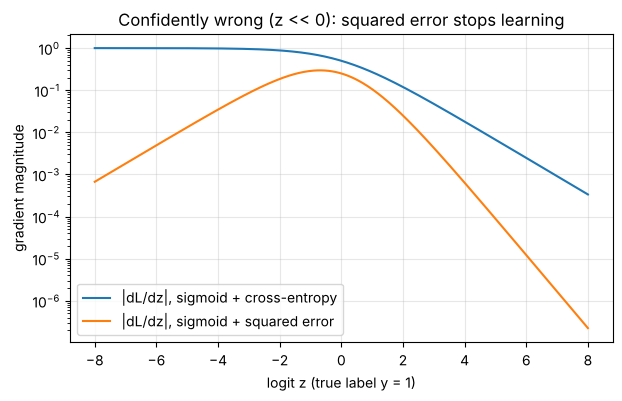

at z = -5.0: CE gradient -0.9933, MSE gradient -0.0132, ratio 75x


In [6]:
zz = np.linspace(-8, 8, 400); y1 = 1.0
grad_ce = sigmoid(zz) - y1                               # BCE on the logit
grad_mse = 2 * (sigmoid(zz) - y1) * sigmoid(zz) * (1 - sigmoid(zz))
plt.plot(zz, np.abs(grad_ce), label="|dL/dz|, sigmoid + cross-entropy")
plt.plot(zz, np.abs(grad_mse), label="|dL/dz|, sigmoid + squared error")
plt.xlabel("logit z (true label y = 1)"); plt.ylabel("gradient magnitude"); plt.yscale("log")
plt.title("Confidently wrong (z << 0): squared error stops learning"); plt.legend(); plt.grid(alpha=0.3); plt.show()
z0 = -5.0
print(f"at z = {z0}: CE gradient {sigmoid(z0) - 1:.4f}, MSE gradient {2 * (sigmoid(z0) - 1) * sigmoid(z0) * (1 - sigmoid(z0)):.4f}, ratio {(sigmoid(z0) - 1) / (2 * (sigmoid(z0) - 1) * sigmoid(z0) * (1 - sigmoid(z0))):.0f}x")

At $z = -5$ with $y = 1$ the squared-error gradient is 75 times smaller than cross-entropy's, and it keeps
shrinking as the model gets *more* wrong. The $\ln$ in the cross-entropy cancels the $\exp$ in the sigmoid;
that cancellation is why classification uses cross-entropy.

## 5. The backward pass: `Dense`, `ReLU`, `MLP`

Reverse mode through a layer $Z = A W + \mathbf{1}b^\top$ needs only Module 06's matrix rules, now with one row
per example. With $G = \partial\mathcal{L}/\partial Z$ of shape $(n \times n_{\text{out}})$:

$$
\frac{\partial\mathcal{L}}{\partial W} = A^\top G \ (n_{\text{in}} \times n_{\text{out}}), \qquad
\frac{\partial\mathcal{L}}{\partial b} = \sum_{\text{rows}} G \ (n_{\text{out}}), \qquad
\frac{\partial\mathcal{L}}{\partial A} = G W^\top \ (n \times n_{\text{in}}),
$$

and an elementwise activation contributes a mask, $G_{\text{in}} = G_{\text{out}} \odot \phi'(Z)$. A layer object stores
what its backward pass needs (its input `X`, or the ReLU mask) during `forward`. A network is a list of
layers run forwards, then backwards in reverse order.

In [7]:
class Dense:
    def __init__(self, n_in, n_out, scale=None, rng=rng):
        scale = np.sqrt(2.0 / n_in) if scale is None else scale          # He initialisation by default
        self.W = rng.normal(0.0, scale, size=(n_in, n_out))
        self.b = np.zeros(n_out)
        self.dW = np.zeros_like(self.W); self.db = np.zeros_like(self.b)
    def forward(self, X):
        self.X = X                                   # keep the input for the weight gradient
        return X @ self.W + self.b
    def backward(self, G):                           # G = dL/dZ, shape (n, n_out)
        self.dW = self.X.T @ G                       # (n_in, n_out)
        self.db = G.sum(axis=0)                      # broadcast in forward -> sum in backward
        return G @ self.W.T                          # dL/dX, shape (n, n_in)
    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]

class ReLU:
    def forward(self, Z):
        self.mask = Z > 0
        return Z * self.mask
    def backward(self, G): return G * self.mask
    def params(self): return []
    def grads(self):  return []

class MLP:
    def __init__(self, layers): self.layers = layers
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X
    def backward(self, G):
        for layer in reversed(self.layers):
            G = layer.backward(G)
        return G                                      # dL/d(input), useful for saliency maps
    def params(self): return [p for l in self.layers for p in l.params()]
    def grads(self):  return [g for l in self.layers for g in l.grads()]

# Section 3's example with squared-error loss L = (1/2n) sum (Z2 - y)^2, targets y = (3, 1)
L1 = Dense(3, 2); L1.W[:] = W1; L1.b[:] = b1
L2 = Dense(2, 1); L2.W[:] = W2; L2.b[:] = b2
net = MLP([L1, ReLU(), L2])
y_t = np.array([[3.], [1.]])
Z2 = net.forward(X)
loss = 0.5 * np.sum((Z2 - y_t) ** 2) / len(X)
G2 = (Z2 - y_t) / len(X)
dX = net.backward(G2)
G1 = (G2 @ L2.W.T) * (Z1 > 0)                   # what ReLU.backward handed to L1 (Z1 from Section 3)
print(f"loss = {loss}\nG2 = dL/dZ2 =\n{G2}\ndW2 =\n{L2.dW}\ndb2 = {L2.db}\nG1 = dL/dZ1 =\n{G1}\ndW1 =\n{L1.dW}\ndb1 = {L1.db}\ndL/dX =\n{dX}")

loss = 0.09250000000000003
G2 = dL/dZ2 =
[[-0.05]
 [ 0.3 ]]
dW2 =
[[ 0.2 ]
 [-0.01]]
db2 = [0.25]
G1 = dL/dZ1 =
[[-0.05  0.05]
 [ 0.3  -0.  ]]
dW1 =
[[-0.05  0.05]
 [ 0.2   0.1 ]
 [-0.3   0.  ]]
db1 = [0.25 0.05]
dL/dX =
[[-0.075 -0.025  0.1  ]
 [ 0.15   0.3    0.   ]]


Every number matches the hand calculation in the concept guide: $\partial\mathcal{L}/\partial W_2 = (0.2, -0.01)^\top$,
$\partial\mathcal{L}/\partial b_2 = 0.25$, and the zero in the bottom-right of $\partial\mathcal{L}/\partial W_1$ — that weight is reached
only through the dead unit of example 2. Now the step you should never skip: a gradient check with central
differences, first on this example and then on a random network with a softmax cross-entropy loss.

In [8]:
def flat_grads(model):
    return np.concatenate([g.ravel() for g in model.grads()])

def grad_check(model, loss_fn, Xb, yb, h=1e-5):
    # loss_fn(Z, yb) -> (loss, dL/dZ). Returns the relative error ||g - g_num|| / (||g|| + ||g_num||).
    Z = model.forward(Xb); loss, G = loss_fn(Z, yb); model.backward(G)
    g = flat_grads(model)
    g_num = np.empty_like(g); k = 0
    for p in model.params():
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + h; lp = loss_fn(model.forward(Xb), yb)[0]
            p[idx] = old - h; lm = loss_fn(model.forward(Xb), yb)[0]
            p[idx] = old
            g_num[k] = (lp - lm) / (2 * h); k += 1
    return np.linalg.norm(g - g_num) / (np.linalg.norm(g) + np.linalg.norm(g_num)), g.size

mse = lambda Z, y: (0.5 * np.sum((Z - y) ** 2) / len(Z), (Z - y) / len(Z))
r, k = grad_check(net, mse, X, y_t)
print(f"Section 3 network, squared error: relative error {r:.1e} over {k} parameters")

check_rng = np.random.default_rng(1)
small = MLP([Dense(8, 6, rng=check_rng), ReLU(), Dense(6, 5, rng=check_rng), ReLU(), Dense(5, 4, rng=check_rng)])
Xb = check_rng.normal(size=(7, 8)); yb = check_rng.integers(0, 4, size=7)
r, k = grad_check(small, softmax_ce, Xb, yb)
print(f"random 8-6-5-4 network, softmax-CE:  relative error {r:.1e} over {k} parameters   (< 1e-7 means the backward pass is right)")

Section 3 network, squared error: relative error 3.4e-12 over 11 parameters
random 8-6-5-4 network, softmax-CE:  relative error 4.3e-11 over 113 parameters   (< 1e-7 means the backward pass is right)


Relative errors around $10^{-10}$: the three backward rules and their composition are correct. If one of
them were wrong — `self.X @ G` instead of `self.X.T @ G`, say — the shape check would catch it; the subtler
`G @ self.W` (wrong shape only when the layer is not square) or a forgotten `.sum(axis=0)` would show up
here as a relative error of order 1. Thirty seconds of checking, and we can trust the gradients that
will drive thousands of updates.

**Try it yourself:** plant a bug — change `return G * self.mask` to `return G` in `ReLU.backward` — and re-run
the check. Then move the bug to `db = G.mean(axis=0)`. How large is each error?

### Training on real data: handwritten digits

`load_digits` has 1,797 images of $8\times 8$ pixels (values 0–16), ten classes. We standardise each pixel using
*training-set* statistics, split 80/20, build a 64 → 128 → 10 ReLU network (9,610 parameters, He-initialised)
and train it with mini-batch Adam (Module 05). Two optimisers are written out so you can see that an
optimiser is just a rule for turning `grads()` into parameter updates. One detail: the hidden layer is
He-initialised because a ReLU follows it, but the *output* layer is linear and we give it a small scale
(0.01) so that the initial logits are near zero and the initial loss is the uninformed value $\ln 10$ —
item 3 of the training recipe in the concept guide.

train (1437, 64), test (360, 64), classes [140 142 141 147 147 143 144 138 145 150]


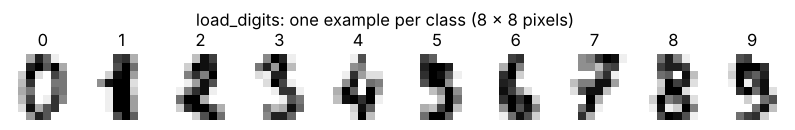

In [9]:
from sklearn.datasets import load_digits

class SGD:
    def __init__(self, model, lr=0.1, momentum=0.9, weight_decay=0.0):
        self.model, self.lr, self.mu, self.wd = model, lr, momentum, weight_decay
        self.v = [np.zeros_like(p) for p in model.params()]
    def step(self):
        for i, (p, g) in enumerate(zip(self.model.params(), self.model.grads())):
            self.v[i] = self.mu * self.v[i] + g + self.wd * p
            p -= self.lr * self.v[i]                         # in-place: the layers see the update

class Adam:
    def __init__(self, model, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.0):
        self.model, self.lr, self.b1, self.b2, self.eps, self.wd = model, lr, beta1, beta2, eps, weight_decay
        self.m = [np.zeros_like(p) for p in model.params()]
        self.v = [np.zeros_like(p) for p in model.params()]
        self.t = 0
    def step(self):
        self.t += 1
        for i, (p, g) in enumerate(zip(self.model.params(), self.model.grads())):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g
            m_hat = self.m[i] / (1 - self.b1 ** self.t)
            v_hat = self.v[i] / (1 - self.b2 ** self.t)
            p -= self.lr * (m_hat / (np.sqrt(v_hat) + self.eps) + self.wd * p)     # AdamW: decoupled decay

digits = load_digits()
X_all, y_all = digits.data, digits.target
split_rng = np.random.default_rng(16)
perm = split_rng.permutation(len(X_all)); n_train = int(0.8 * len(X_all))
X_tr, y_tr = X_all[perm[:n_train]], y_all[perm[:n_train]]
X_te, y_te = X_all[perm[n_train:]], y_all[perm[n_train:]]
mu, sd = X_tr.mean(axis=0), X_tr.std(axis=0)
sd[sd == 0] = 1.0                                     # three corner pixels are constant zero
X_tr = (X_tr - mu) / sd; X_te = (X_te - mu) / sd
print(f"train {X_tr.shape}, test {X_te.shape}, classes {np.bincount(y_tr)}")

fig, axes = plt.subplots(1, 10, figsize=(10, 1.6))
for d, ax in enumerate(axes):
    ax.imshow(digits.images[np.where(y_all == d)[0][0]], cmap="gray_r"); ax.set_title(str(d)); ax.axis("off")
fig.suptitle("load_digits: one example per class (8 x 8 pixels)"); plt.show()

parameters: 9610    initial loss: 2.328  (ln 10 = 2.303 )


epoch  0  train loss 0.5721  test loss 0.5638  train acc 0.8838  test acc 0.8694


epoch  5  train loss 0.0419  test loss 0.0843  train acc 0.9958  test acc 0.9778


epoch 10  train loss 0.0132  test loss 0.0691  train acc 1.0000  test acc 0.9806


epoch 15  train loss 0.0062  test loss 0.0667  train acc 1.0000  test acc 0.9833


epoch 20  train loss 0.0037  test loss 0.0659  train acc 1.0000  test acc 0.9833


epoch 25  train loss 0.0024  test loss 0.0666  train acc 1.0000  test acc 0.9833


epoch 29  train loss 0.0018  test loss 0.0660  train acc 1.0000  test acc 0.9833
training time 7.3s   final test accuracy 0.9833


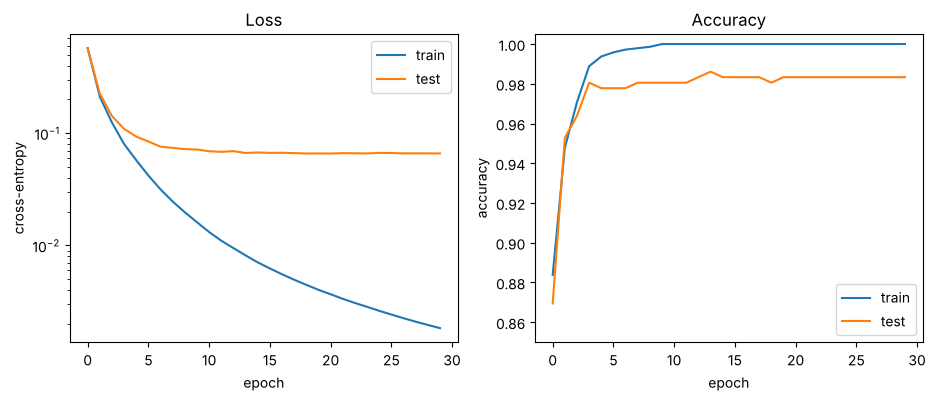

In [10]:
def accuracy(model, Xs, ys):
    return float(np.mean(model.forward(Xs).argmax(axis=1) == ys))

def train(model, opt, X_tr, y_tr, X_te, y_te, epochs=30, batch_size=64, rng=rng, verbose=True):
    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(epochs):
        order = rng.permutation(len(X_tr))                        # reshuffle every epoch
        for start in range(0, len(X_tr), batch_size):
            idx = order[start:start + batch_size]
            Z = model.forward(X_tr[idx])                          # forward
            loss, G = softmax_ce(Z, y_tr[idx])                    # loss and dL/dZ
            model.backward(G)                                     # gradients into every layer
            opt.step()                                            # update
        hist["train_loss"].append(softmax_ce(model.forward(X_tr), y_tr)[0])
        hist["test_loss"].append(softmax_ce(model.forward(X_te), y_te)[0])
        hist["train_acc"].append(accuracy(model, X_tr, y_tr)); hist["test_acc"].append(accuracy(model, X_te, y_te))
        if verbose and (epoch % 5 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch:2d}  train loss {hist['train_loss'][-1]:.4f}  test loss {hist['test_loss'][-1]:.4f}  "
                  f"train acc {hist['train_acc'][-1]:.4f}  test acc {hist['test_acc'][-1]:.4f}")
    return hist

model_rng = np.random.default_rng(0)
model = MLP([Dense(64, 128, rng=model_rng), ReLU(), Dense(128, 10, scale=0.01, rng=model_rng)])   # He for the ReLU layer; small output layer
print("parameters:", sum(p.size for p in model.params()), "   initial loss:", round(softmax_ce(model.forward(X_tr), y_tr)[0], 3), " (ln 10 =", round(np.log(10), 3), ")")
t0 = time.time()
hist = train(model, Adam(model, lr=3e-3), X_tr, y_tr, X_te, y_te, epochs=30, rng=np.random.default_rng(1))
print(f"training time {time.time() - t0:.1f}s   final test accuracy {hist['test_acc'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist["train_loss"], label="train"); axes[0].plot(hist["test_loss"], label="test")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(hist["train_acc"], label="train"); axes[1].plot(hist["test_acc"], label="test")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy"); axes[1].set_ylim(0.85, 1.005); axes[1].legend()
plt.show()

Around 97–98 percent test accuracy in a few seconds of NumPy — from a loss that started at $\ln 10 = 2.30$,
as every uninformed 10-class model should (check this number every time; a very different value means the
output layer is badly scaled, or there is a bug in the loss or the labels). Read the curves the way Section 9
of the guide describes: the training loss keeps falling towards zero while the test loss bottoms out after
about a dozen epochs and then creeps up slightly — the model is becoming over-confident on the few examples
it gets wrong, without changing which ones. Early stopping at the test minimum would cost nothing in accuracy.
And note the scale of the claim: 360 test examples give a standard error of about 0.8 percentage points on the
accuracy, so differences of half a percent between runs are noise.

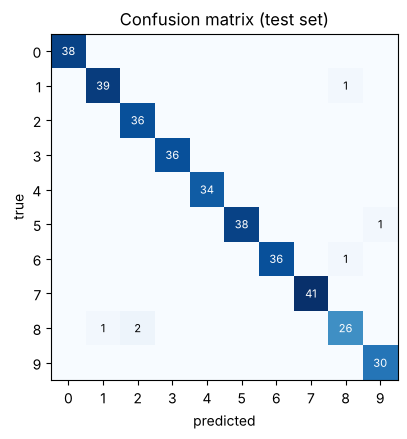

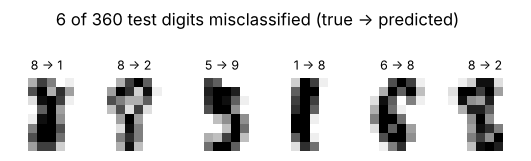

In [11]:
pred = model.forward(X_te).argmax(axis=1)
conf = np.zeros((10, 10), int)
for t, p in zip(y_te, pred):
    conf[t, p] += 1
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(conf, cmap="Blues"); ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test set)")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        if conf[i, j]:
            ax.text(j, i, conf[i, j], ha="center", va="center", color="white" if conf[i, j] > 20 else "black", fontsize=8)
plt.show()

wrong = np.where(pred != y_te)[0]
fig, axes = plt.subplots(1, max(len(wrong[:10]), 1), figsize=(1.1 * max(len(wrong[:10]), 1), 1.8))
for ax, i in zip(np.atleast_1d(axes), wrong[:10]):
    ax.imshow((X_te[i] * sd + mu).reshape(8, 8), cmap="gray_r"); ax.set_title(f"{y_te[i]} -> {pred[i]}", fontsize=9); ax.axis("off")
fig.suptitle(f"{len(wrong)} of {len(y_te)} test digits misclassified (true -> predicted)", y=1.08); plt.show()

Most of the errors are genuinely ambiguous $8\times8$ blobs — eights read as ones or nines, threes as fives.
A convolutional network would recover perhaps a percentage point here; the remaining errors are in the
data, not the model.

**Try it yourself:** replace `Adam(model, lr=3e-3)` by `SGD(model, lr=0.02, momentum=0.9)` and compare the
curves; then try a 64–128–64–10 network, and `weight_decay=1e-2` in Adam. Which changes move the *test* loss?

## 6. Initialisation and variance propagation

For a pre-activation $z = \sum_{j=1}^{n_{\text{in}}} w_j x_j$ with independent zero-mean weights and inputs,

$$
\operatorname{Var}(z) = n_{\text{in}}\, \sigma_w^2\, \sigma_x^2 ,
$$

so each layer multiplies the signal variance by $n_{\text{in}} \sigma_w^2$ — and a ReLU then halves the second moment.
Preserving the scale needs $\sigma_w^2 = 1/n_{\text{in}}$ for linear/tanh layers (LeCun; Xavier averages fan-in and
fan-out) and $\sigma_w^2 = 2/n_{\text{in}}$ for ReLU (He). Let us push a batch through 10 layers of width 256 with four
weight scales and record the standard deviation of the activations at each depth.

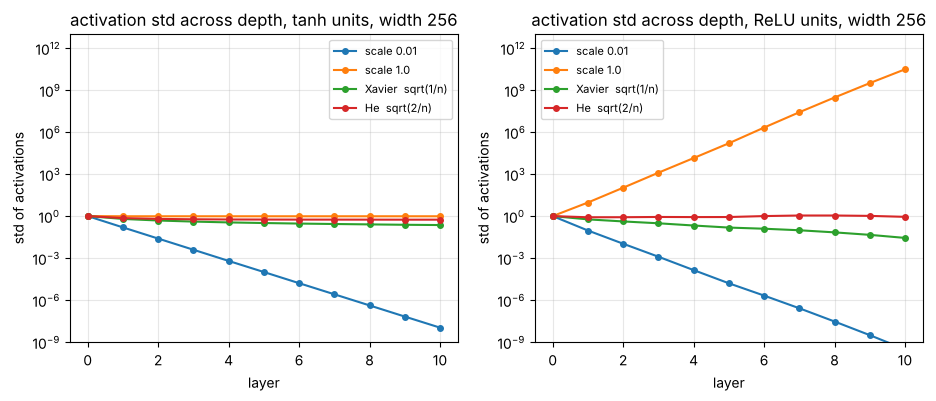

scale 0.01           n*sigma_w^2 =   0.0256   tanh std after 10 layers 1.08e-08   ReLU std after 10 layers 3.05e-10
scale 1.0            n*sigma_w^2 = 256.0000   tanh std after 10 layers 9.74e-01   ReLU std after 10 layers 3.05e+10
Xavier  sqrt(1/n)    n*sigma_w^2 =   1.0000   tanh std after 10 layers 2.30e-01   ReLU std after 10 layers 2.77e-02
He  sqrt(2/n)        n*sigma_w^2 =   2.0000   tanh std after 10 layers 5.57e-01   ReLU std after 10 layers 8.87e-01


In [12]:
def activation_stats(scale, depth=10, width=256, act=np.tanh, n=512, seed=0):
    r = np.random.default_rng(seed)
    A = r.normal(size=(n, width)); stds = [A.std()]
    for _ in range(depth):
        W = r.normal(0.0, scale, size=(width, width))
        A = act(A @ W); stds.append(A.std())
    return np.array(stds)

width = 256
relu_f = lambda z: np.maximum(z, 0.0)
schemes = {"scale 0.01": 0.01, "scale 1.0": 1.0, "Xavier  sqrt(1/n)": np.sqrt(1 / width), "He  sqrt(2/n)": np.sqrt(2 / width)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, act, name in zip(axes, [np.tanh, relu_f], ["tanh", "ReLU"]):
    for label, s in schemes.items():
        ax.semilogy(activation_stats(s, act=act), "o-", ms=4, label=label)
    ax.set_title(f"activation std across depth, {name} units, width {width}"); ax.set_xlabel("layer"); ax.set_ylabel("std of activations")
    ax.set_ylim(1e-9, 1e13); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
for label, s in schemes.items():
    print(f"{label:20s} n*sigma_w^2 = {width * s**2:8.4f}   tanh std after 10 layers {activation_stats(s)[-1]:.2e}   ReLU std after 10 layers {activation_stats(s, act=relu_f)[-1]:.2e}")

Scale 0.01 multiplies the variance by $256 \times 10^{-4} = 0.0256$ per layer — after ten layers the activations are
$10^{-8}$, and so are the gradients that flow back through the same matrices. Scale 1.0 multiplies the variance
by 256 per layer (128 after the ReLU halves it), so the ReLU activations grow by a factor of about 11 per layer
to $10^{10}$ after ten; the gradients grow the same way, and the first update is a huge step in a random
direction. The tanh chain does not blow up — its units saturate at $\pm 1$ instead, which kills the gradient a
different way. Xavier keeps tanh activations at a constant scale but lets ReLU activations shrink by $\sqrt{1/2}$
per layer; He's extra factor of 2 compensates for the half of the signal the ReLU discards. The right scale is
not a tuning knob — it is $n_{\text{in}} \sigma_w^2 = 1$ or $2$, which you compute.

**Try it yourself:** set `depth=50`. Which schemes survive? Then try `act=lambda z: np.where(z > 0, z, 0.1 * z)`
(leaky ReLU) with the He scale and with $\sqrt{2/(1 + 0.1^2)/n}$.

## 7. Vanishing and exploding gradients, and the residual fix

The gradient reaching layer $l$ is the output gradient times a product of $L - l$ Jacobians, each
$\operatorname{diag}(\phi'(Z))\,W^\top$ in row form. Sigmoid's $\phi' \le 1/4$ makes the product shrink by at least 4 per layer
whatever the weights; ReLU's mask is 0 or 1 and lets the active paths through undiminished. A residual block
$A_{l} = A_{l-1} + F(A_{l-1})$ has Jacobian $I + J_l$, so the product $\prod_l (I + J_l) = I + \sum_l J_l + \cdots$
always contains an identity path. Let us measure $\lVert \partial\mathcal{L}/\partial A_l \rVert$ at every depth of a 20-layer chain.

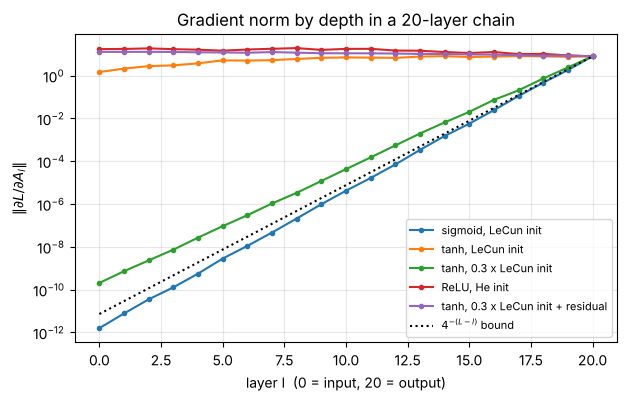

sigmoid, LeCun init                  gradient at input / gradient at output = 1.99e-13
tanh, LeCun init                     gradient at input / gradient at output = 1.84e-01
tanh, 0.3 x LeCun init               gradient at input / gradient at output = 2.57e-11
ReLU, He init                        gradient at input / gradient at output = 2.17e+00
tanh, 0.3 x LeCun init + residual    gradient at input / gradient at output = 1.62e+00


In [13]:
def gradient_norms_by_layer(Ws, act, dact, x, residual=False):
    # forward through the chain, then reverse mode; returns ||dL/dA_l|| for l = 0..L with L = sum of outputs
    A = x.copy(); Zs = []
    for W in Ws:
        Z = A @ W; Zs.append(Z)
        A = A + act(Z) if residual else act(Z)
    G = np.ones_like(A); norms = [np.linalg.norm(G)]
    for W, Z in zip(reversed(Ws), reversed(Zs)):
        Gz = G * dact(Z)
        G = Gz @ W.T + (G if residual else 0.0)
        norms.append(np.linalg.norm(G))
    return np.array(norms[::-1])            # index l = layer input, 0 = network input

depth, width = 20, 64
r = np.random.default_rng(7)
x0 = r.normal(size=width)
W_lecun = [r.normal(0, np.sqrt(1 / width), (width, width)) for _ in range(depth)]
W_he = [r.normal(0, np.sqrt(2 / width), (width, width)) for _ in range(depth)]
W_small = [r.normal(0, 0.3 * np.sqrt(1 / width), (width, width)) for _ in range(depth)]
dsig = lambda z: sigmoid(z) * (1 - sigmoid(z)); dtanh = lambda z: 1 - np.tanh(z) ** 2; drelu = lambda z: (z > 0).astype(float)

curves = {
    "sigmoid, LeCun init":               gradient_norms_by_layer(W_lecun, sigmoid, dsig, x0),
    "tanh, LeCun init":                  gradient_norms_by_layer(W_lecun, np.tanh, dtanh, x0),
    "tanh, 0.3 x LeCun init":            gradient_norms_by_layer(W_small, np.tanh, dtanh, x0),
    "ReLU, He init":                     gradient_norms_by_layer(W_he, relu_f, drelu, x0),
    "tanh, 0.3 x LeCun init + residual": gradient_norms_by_layer(W_small, np.tanh, dtanh, x0, residual=True),
}
for label, c in curves.items():
    plt.semilogy(range(depth + 1), c, "o-", ms=3, label=label)
plt.semilogy(range(depth + 1), curves["sigmoid, LeCun init"][-1] * 0.25 ** np.arange(depth, -1, -1), "k:", label=r"$4^{-(L-l)}$ bound")
plt.xlabel("layer l  (0 = input, 20 = output)"); plt.ylabel(r"$\|\partial L / \partial A_l\|$"); plt.title("Gradient norm by depth in a 20-layer chain")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()
for label, c in curves.items():
    print(f"{label:36s} gradient at input / gradient at output = {c[0] / c[-1]:.2e}")

The sigmoid chain loses about thirteen orders of magnitude in twenty layers, tracking the $4^{-(L-l)}$ bound;
its first layers would never learn. The tanh chain with weights a bit too small loses more than ten orders —
vanishing is not only a sigmoid problem, it is a *scale* problem. ReLU with He initialisation and tanh with the right
scale both keep the gradient within a factor of a few across the whole depth. And the residual connection
rescues even the badly scaled tanh chain: the identity path guarantees the gradient at the input is at
least of the order of the gradient at the output, whatever the branches do. That one line, `A + act(Z)`,
is why 100-layer networks train today.

Exploding gradients are the mirror image (replace the He weights by `np.sqrt(2.2 / width)`, ten percent too
large, and the ReLU curve climbs instead); gradient clipping, `g *= min(1, c / ||g||)`, is the usual seat belt.

## 8. Batch normalisation

Instead of hoping the weights keep activations at a sensible scale, batch norm *re-standardises* every
pre-activation over the mini-batch and lets the network choose a new scale and shift:

$$
\mu_j = \frac1n\sum_i Z_{ij}, \quad \sigma_j^2 = \frac1n\sum_i (Z_{ij} - \mu_j)^2, \quad
\hat Z_{ij} = \frac{Z_{ij} - \mu_j}{\sqrt{\sigma_j^2 + \epsilon}}, \quad Y_{ij} = \gamma_j \hat Z_{ij} + \beta_j .
$$

During training it also keeps running averages of $\mu$ and $\sigma^2$, which replace the batch statistics at
inference time, so a single example gets a deterministic output. The backward pass must go through $\mu$ and
$\sigma^2$ as well (they depend on every row); the formula is in the guide, and we check it numerically.

y = [-1.1381 -0.069   1.      4.2071]   running mean [0.3]  running var (unbiased, after one update) [1.3667]
scale invariance: same inputs x100 -> [-1.1381 -0.069   1.      4.2071]
gradient check through BatchNorm (training mode): relative error 4.7e-11 over 63 parameters


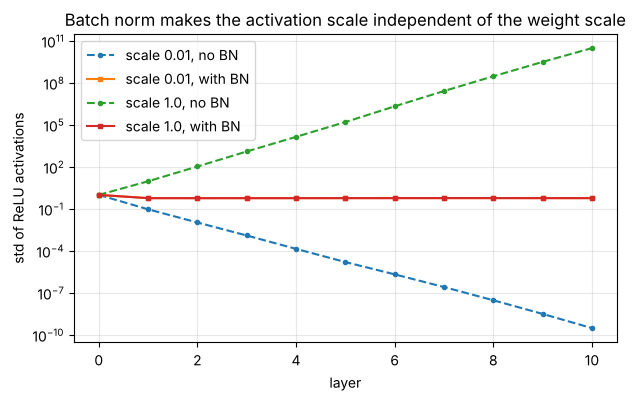

In [14]:
class BatchNorm:
    def __init__(self, n_features, eps=1e-5, momentum=0.1):
        self.gamma = np.ones(n_features); self.beta = np.zeros(n_features)
        self.dgamma = np.zeros(n_features); self.dbeta = np.zeros(n_features)
        self.eps, self.momentum = eps, momentum
        self.running_mean = np.zeros(n_features); self.running_var = np.ones(n_features)
        self.training = True
    def forward(self, Z):
        if self.training:
            mu = Z.mean(axis=0); var = Z.var(axis=0)
            n = Z.shape[0]
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mu
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * var * n / max(n - 1, 1)
        else:
            mu, var = self.running_mean, self.running_var
        self.inv_std = 1.0 / np.sqrt(var + self.eps)
        self.Zhat = (Z - mu) * self.inv_std
        return self.gamma * self.Zhat + self.beta
    def backward(self, G):
        n = G.shape[0]
        self.dgamma = (G * self.Zhat).sum(axis=0); self.dbeta = G.sum(axis=0)
        return self.gamma * self.inv_std / n * (n * G - G.sum(axis=0) - self.Zhat * (G * self.Zhat).sum(axis=0))
    def params(self): return [self.gamma, self.beta]
    def grads(self):  return [self.dgamma, self.dbeta]

# (a) the worked example: one unit, batch (1, 2, 3, 6), gamma = 2, beta = 1
bn = BatchNorm(1); bn.gamma[:] = 2.0; bn.beta[:] = 1.0
Zb = np.array([[1.], [2.], [3.], [6.]])
print("y =", bn.forward(Zb).ravel(), "  running mean", bn.running_mean, " running var (unbiased, after one update)", bn.running_var)
print("scale invariance: same inputs x100 ->", bn.forward(100 * Zb).ravel())

# (b) gradient check of the backward pass inside a small network
bn_rng = np.random.default_rng(3)
bn_net = MLP([Dense(6, 5, rng=bn_rng), BatchNorm(5), ReLU(), Dense(5, 3, rng=bn_rng)])
Xb = bn_rng.normal(size=(8, 6)) * 3 + 1; yb = bn_rng.integers(0, 3, size=8)
r_bn, k_bn = grad_check(bn_net, softmax_ce, Xb, yb)
print(f"gradient check through BatchNorm (training mode): relative error {r_bn:.1e} over {k_bn} parameters")

# (c) effect on activation statistics in a deep, badly initialised chain
def deep_stats(use_bn, scale=1.0, depth=10, width=256, n=512, seed=0):
    r = np.random.default_rng(seed); A = r.normal(size=(n, width)); stds = [A.std()]
    for _ in range(depth):
        Z = A @ r.normal(0, scale, size=(width, width))
        if use_bn:
            Z = BatchNorm(width).forward(Z)
        A = relu_f(Z); stds.append(A.std())
    return np.array(stds)
for scale in (0.01, 1.0):
    plt.semilogy(deep_stats(False, scale), "o--", ms=3, label=f"scale {scale}, no BN")
    plt.semilogy(deep_stats(True, scale), "s-", ms=3, label=f"scale {scale}, with BN")
plt.xlabel("layer"); plt.ylabel("std of ReLU activations"); plt.title("Batch norm makes the activation scale independent of the weight scale")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Three facts in one cell. The worked example reproduces the guide ($y = (-1.138, -0.069, 1, 4.207)$) and shows
the scale invariance — multiply the inputs by 100 and the output is identical. The backward pass, which
removes from the gradient the components that would change the batch mean and variance, passes the
gradient check to $10^{-10}$. And with batch norm the activation statistics across ten layers are the same
whether the weights are a hundred times too small or not: the layer after a batch norm never has to care
what happened upstream, which is what lets you raise the learning rate by an order of magnitude.

Switch `bn.training = False` before serving predictions. With `training = True` and a batch of one, $\hat Z = 0$
for every unit and the network outputs a constant — one of the most common deployment bugs in practice.

## 10. Dropout against overfitting

Inverted dropout keeps each hidden activation with probability $q = 1 - p$ and divides the survivors by $q$,
so $E[\tilde A] = A$ and the layer can simply be switched off at test time. We make the problem hard on purpose:
train a 64 → 256 → 10 network (19,210 parameters) on only **100** digits, full-batch, for 400 Adam steps at a
deliberately brisk learning rate of $10^{-2}$, and compare the test loss with and without dropout on the hidden
layer. (Dropout is active only in training mode; the losses below are evaluated with it switched off.)

no dropout                           final train loss 0.0000   final test loss 0.6325   min test loss 0.4698 at step 7   test acc 0.883


dropout p = 0.5                      final train loss 0.0000   final test loss 0.5769   min test loss 0.4723 at step 8   test acc 0.889


dropout p = 0.5 + weight decay 0.1   final train loss 0.0001   final test loss 0.3868   min test loss 0.3832 at step 314   test acc 0.886


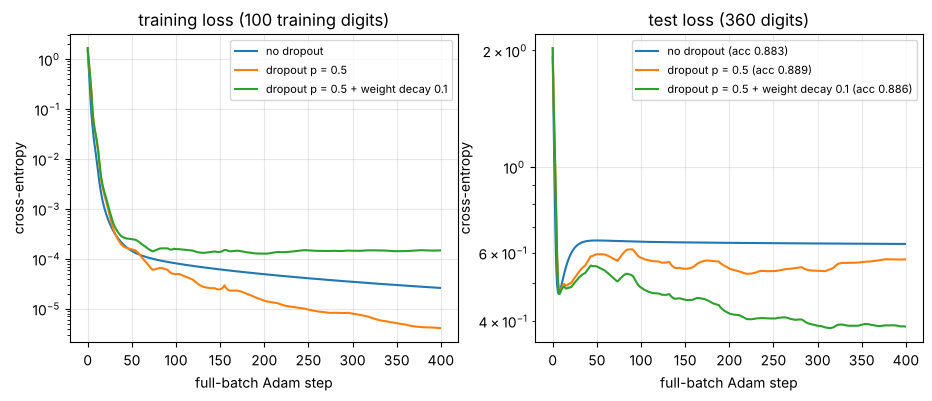

In [15]:
class Dropout:
    def __init__(self, p=0.5, rng=rng):
        self.p, self.rng, self.training = p, rng, True
    def forward(self, A):
        if not self.training or self.p == 0:
            self.mask = 1.0
        else:
            self.mask = (self.rng.random(A.shape) >= self.p) / (1 - self.p)      # inverted dropout
        return A * self.mask
    def backward(self, G): return G * self.mask
    def params(self): return []
    def grads(self):  return []

def set_training(model, flag):
    for layer in model.layers:
        if hasattr(layer, "training"):
            layer.training = flag

def small_data_run(p_drop, weight_decay=0.0, n_small=100, steps=400, seed=0):
    r = np.random.default_rng(seed)
    Xs, ys = X_tr[:n_small], y_tr[:n_small]
    model = MLP([Dense(64, 256, rng=r), ReLU(), Dropout(p_drop, rng=r), Dense(256, 10, rng=r)])
    opt = Adam(model, lr=1e-2, weight_decay=weight_decay)
    tr, te = [], []
    for step in range(steps):
        set_training(model, True)
        loss, G = softmax_ce(model.forward(Xs), ys); model.backward(G); opt.step()
        set_training(model, False)
        tr.append(softmax_ce(model.forward(Xs), ys)[0]); te.append(softmax_ce(model.forward(X_te), y_te)[0])
    return np.array(tr), np.array(te), accuracy(model, X_te, y_te)

runs = {"no dropout": (0.0, 0.0), "dropout p = 0.5": (0.5, 0.0), "dropout p = 0.5 + weight decay 0.1": (0.5, 0.1)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, (p_drop, wd) in runs.items():
    tr, te, acc = small_data_run(p_drop, wd)
    axes[0].plot(tr, label=label); axes[1].plot(te, label=f"{label} (acc {acc:.3f})")
    print(f"{label:36s} final train loss {tr[-1]:.4f}   final test loss {te[-1]:.4f}   min test loss {te.min():.4f} at step {te.argmin()}   test acc {acc:.3f}")
axes[0].set_title("training loss (100 training digits)"); axes[1].set_title("test loss (360 digits)")
for ax in axes:
    ax.set_xlabel("full-batch Adam step"); ax.set_ylabel("cross-entropy"); ax.set_yscale("log"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

Without dropout the network memorises the 100 digits within a few steps (training loss $\to 0$) and the test
loss reaches its minimum almost immediately and then climbs for the rest of the run — classic overfitting. With
dropout the training loss falls more slowly, the test loss keeps improving for most of the run and ends well
below the unregularised curve, and weight decay lowers it further still and removes the upturn entirely. The
accuracy gain is a few percentage points; with 100 examples that is what regularisation can buy. The *shape*
of the curves is the lesson: regularisation trades training fit for a test curve that does not turn around.

**Try it yourself:** set `n_small=1000`. Does dropout still help, or does the gap close once there is enough data?

## 11. Beyond MLPs: convolution is a `Dense` layer with structure

A 1-D cross-correlation $y_i = \sum_{j} w_j x_{i+j}$ is the product $y = Tx$ with a *Toeplitz* matrix $T$ whose rows are
shifted copies of the kernel. So a convolutional layer is a `Dense` layer whose weight matrix is sparse (each output
sees $m$ inputs — its receptive field) and whose non-zero entries are shared along the diagonals. Let us build $T$,
check it against `np.convolve`, and derive the backward pass from the Toeplitz form.

In [16]:
def toeplitz_conv_matrix(w, n):
    m = len(w)
    T = np.zeros((n - m + 1, n))
    for i in range(n - m + 1):
        T[i, i:i + m] = w
    return T

x_sig = np.array([1., 2., 3., 4., 2., 0., -1.])
w_k = np.array([1., -1., 0.5])
T = toeplitz_conv_matrix(w_k, len(x_sig))
y_T = T @ x_sig
y_np = np.convolve(x_sig, w_k[::-1], mode="valid")     # np.convolve flips the kernel; flip it back for cross-correlation
print("Toeplitz matrix T =\n", T)
print("T @ x          =", y_T)
print("np.convolve    =", y_np, "   max difference", np.max(np.abs(y_T - y_np)))
print(f"parameters: kernel {w_k.size} vs. unconstrained dense layer {T.size}")

# backward pass from the Toeplitz form, for an upstream gradient G on y
G_y = rng.normal(size=len(y_T))
dx = T.T @ G_y                                                                 # = full convolution of G with the flipped kernel
dx_conv = np.convolve(G_y, w_k, mode="full")
dw = np.array([G_y @ x_sig[j:j + len(y_T)] for j in range(len(w_k))])          # shared weight: sum over all positions
print("dL/dx via T^T G  =", dx)
print("dL/dx via conv   =", dx_conv, "   max difference", np.max(np.abs(dx - dx_conv)))
print("dL/dw (sum of per-position contributions) =", dw)

# receptive field: stack three kernel-3 layers and see which inputs one output depends on
T3 = toeplitz_conv_matrix(np.ones(3), 9) ; T2 = toeplitz_conv_matrix(np.ones(3), 7); T1 = toeplitz_conv_matrix(np.ones(3), 5)
print("non-zero pattern of (T1 @ T2 @ T3)[0] after three 3-wide convolutions:", (T1 @ T2 @ T3)[0] != 0, " -> receptive field 7")

Toeplitz matrix T =
 [[ 1.  -1.   0.5  0.   0.   0.   0. ]
 [ 0.   1.  -1.   0.5  0.   0.   0. ]
 [ 0.   0.   1.  -1.   0.5  0.   0. ]
 [ 0.   0.   0.   1.  -1.   0.5  0. ]
 [ 0.   0.   0.   0.   1.  -1.   0.5]]
T @ x          = [0.5 1.  0.  2.  1.5]
np.convolve    = [0.5 1.  0.  2.  1.5]    max difference 0.0
parameters: kernel 3 vs. unconstrained dense layer 35
dL/dx via T^T G  = [-0.6655  0.8977 -0.4482  0.2181  0.7111 -0.7621  0.4357]
dL/dx via conv   = [-0.6655  0.8977 -0.4482  0.2181  0.7111 -0.7621  0.4357]    max difference 0.0
dL/dw (sum of per-position contributions) = [ 2.7665  0.2696 -1.7059]
non-zero pattern of (T1 @ T2 @ T3)[0] after three 3-wide convolutions: [ True  True  True  True  True  True  True False False]  -> receptive field 7


Same numbers from the matrix and from `np.convolve`, and the backward pass falls straight out of Section 5:
$\partial\mathcal{L}/\partial x = T^\top G$ is a convolution with the *flipped* kernel, and the gradient of each shared weight
is the sum of the gradients of all its copies (broadcast ⇒ sum, exactly as for the bias). Three layers of
width-3 kernels give every output a receptive field of 7 inputs; that additive growth is how a pixel at the
top of a ResNet "sees" the whole image. A recurrent network is the same story with the same matrix applied
at every time step (so its gradients behave like $\sigma_{\max}(W)^{T}$), an embedding layer is a `Dense` layer fed
one-hot rows, and attention is a `Dense` layer whose position-mixing matrix is computed from the data —
Module 17.

## Summary

* A hidden layer turns "which side of which lines" into new coordinates in which a linear output layer
  works; XOR needs it, and so does everything interesting. No nonlinearity ⇒ the whole stack is one affine map.
* Activations are chosen by their derivatives: sigmoid $\le 1/4$, tanh $\le 1$, ReLU/SiLU/GELU $\approx 1$ on the active side.
* Batch-first shapes: $Z = XW + b$ with $X: n \times n_{\text{in}}$, $W: n_{\text{in}} \times n_{\text{out}}$; forward cost
  $\approx 2 \cdot \text{weights} \cdot \text{batch}$ FLOPs.
* Softmax cross-entropy with log-sum-exp is stable, starts at $\ln k$, and has gradient $(P - Y)/n$; sigmoid plus
  squared error vanishes exactly where the model is most wrong.
* Backward pass: $\partial W = A^\top G$, $\partial b = \sum_{\text{rows}} G$, $\partial A = G W^\top$, mask through the activation —
  three rules, verified to $10^{-10}$ by central differences, trained to 97 percent on the digits.
* Initialisation is a calculation: $\operatorname{Var}(z) = n_{\text{in}} \sigma_w^2 \sigma_x^2$, so $\sigma_w^2 = 1/n_{\text{in}}$ (tanh) or
  $2/n_{\text{in}}$ (ReLU); scale 0.01 or 1.0 at width 256 loses or gains eight orders of magnitude in ten layers.
* Gradients through depth are products of Jacobians: sigmoid chains vanish like $4^{-L}$, badly scaled tanh
  chains too; ReLU + He, batch norm and residual connections ($I + J$) keep the product near 1.
* Batch norm standardises per unit over the batch, has a non-trivial backward pass, is scale-invariant, and
  must use running statistics at inference.
* Inverted dropout is multiplicative noise with $E[\tilde A] = A$; on 100 training digits it stops the test loss
  from turning upward.
* Convolution is a Toeplitz `Dense` layer; its backward pass is the transposed (flipped-kernel) convolution
  and a sum over the shared weights' positions.

**Next:** open `exercises.ipynb` and build the pieces yourself — activations, the stable loss, `Dense.backward`
with a gradient check, He initialisation, batch norm, dropout, convolution-as-a-matrix, and finally your own
regularised digit classifier with a bootstrap confidence interval.